# Etapa 3 — Modelos convexos: regresión logística y SVM

Esta etapa cubre:

1. **Bonn, 3 clases** (sano / interictal / ictal): regresión logística multinomial (softmax) y SVM.
   Matriz de confusión, ROC y AUC, y las probabilidades sobre el **simplex**.
2. **Optimalidad global**: la pérdida logística con regularización L2 es estrictamente convexa,
   así que el descenso por gradiente llega al mismo mínimo desde cualquier punto inicial. Se
   contrasta con una red neuronal chica (no convexa).
3. **Multiplicadores de Lagrange**: dual del SVM y verificación numérica de las condiciones KKT;
   deducción de softmax; umbral de **Neyman-Pearson**.
4. **CHB-MIT**: detección por paciente nuevo (*leave-one-patient-out*), sensibilidad,
   especificidad, falsas alarmas por hora y latencia.

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.special import expit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             accuracy_score, balanced_accuracy_score, f1_score)

warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    RAIZ = Path("/content/drive/MyDrive/TP_Machine_Learning_Epilepsia")
except ImportError:
    RAIZ = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import metricas as M
import estilo_graficos as EG
EG.aplicar()

SALIDA = RAIZ / "resultados" / "etapa3"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLA = 0
print("RAIZ:", RAIZ)

RAIZ: D:\Universidad De Palermo - Maestria en IA\Machine Learning\TP_Machine_Learning_Epilepsia


## Parte A — Bonn, 3 clases

### A.1 Atributos: log-potencia en bandas de 2 Hz

Sobre las señales filtradas a 40 Hz de la Etapa 1 se estima la densidad espectral con Welch y se integra
en 20 bandas: $[0{,}5, 2), [2, 4), \dots, [38, 40)$ Hz. Cada segmento queda representado por

$$\mathbf{x} = \big(\log_{10} P_{[0.5,2)},\ \log_{10} P_{[2,4)},\ \dots,\ \log_{10} P_{[38,40)}\big) \in \mathbb{R}^{20}.$$

Clases: **sano** = A + B (200 segmentos), **interictal** = C + D (200), **ictal** = E (100).

In [2]:
d = np.load(RAIZ / "resultados" / "etapa1" / "bonn_filtrado_40hz.npz")
Xb, set_b, FS_B = d["X"], d["y"], float(d["fs"])
CLASES = ["sano", "interictal", "ictal"]
y3 = np.select([np.isin(set_b, ["A", "B"]), np.isin(set_b, ["C", "D"])], [0, 1], 2)

f, Pxx = signal.welch(Xb, fs=FS_B, window="hann", nperseg=512, noverlap=256, axis=-1)
BORDES = np.array([0.5] + list(range(2, 42, 2)), dtype=float)
CENTROS = (BORDES[:-1] + BORDES[1:]) / 2
Fb = np.log10(np.stack([np.trapezoid(Pxx[:, (f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)], axis=-1)
                        for lo, hi in zip(BORDES[:-1], BORDES[1:])], axis=1) + 1e-6)
print("Atributos Bonn:", Fb.shape, "| clases:", np.bincount(y3))

Atributos Bonn: (500, 20) | clases: [200 200 100]


### A.2 Regresión logística multinomial: softmax deducido con Lagrange

El modelo calcula un puntaje lineal por clase, $z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$, y lo convierte
en probabilidades $\mathbf{p} \in \Delta^2 = \{\mathbf{p} \in \mathbb{R}^3 : p_k \ge 0,\ \sum_k p_k = 1\}$
(el **simplex** de probabilidades).

**Softmax como problema con restricciones.** Entre todas las distribuciones del simplex, se busca la que
maximiza el puntaje esperado más la entropía:

$$\max_{\mathbf{p}} \ \sum_k p_k z_k - \sum_k p_k \log p_k \quad \text{s.a.} \quad \sum_k p_k = 1.$$

Lagrangiano: $\mathcal{L}(\mathbf{p}, \nu) = \sum_k p_k z_k - \sum_k p_k \log p_k + \nu\big(\sum_k p_k - 1\big)$.

$$\frac{\partial \mathcal{L}}{\partial p_k} = z_k - \log p_k - 1 + \nu = 0 \ \Rightarrow\ p_k = e^{\nu - 1} e^{z_k}.$$

Imponiendo $\sum_k p_k = 1$ se obtiene $e^{\nu-1} = 1 / \sum_j e^{z_j}$, es decir

$$p_k = \operatorname{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_j e^{z_j}}.$$

La positividad $p_k > 0$ sale gratis (la exponencial es positiva), así que esa restricción no está activa.

**Entrenamiento.** Se minimiza la entropía cruzada con regularización L2:

$$J(W, \mathbf{b}) = -\frac{1}{n}\sum_{i=1}^{n} \log p_{y_i}(\mathbf{x}_i) + \frac{\lambda}{2}\lVert W \rVert_F^2.$$

### A.3 Validación cruzada estratificada

10 particiones estratificadas, repetidas 5 veces con distinto orden. **Limitación:** Bonn no informa qué
segmento es de qué paciente (5 pacientes por set), así que segmentos del mismo paciente pueden quedar en
entrenamiento y prueba a la vez. Las métricas de Bonn son optimistas; la evaluación honesta por paciente
se hace con CHB-MIT (Parte D).

In [3]:
MODELOS_BONN = {
    "logistica": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)),
    "svm_lineal": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "svm_rbf": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10.0, gamma="scale")),
}
rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=SEMILLA)
filas = []
for nombre, modelo in MODELOS_BONN.items():
    r = cross_validate(modelo, Fb, y3, cv=rcv, scoring=["accuracy", "balanced_accuracy", "f1_macro"])
    filas.append({"modelo": nombre,
                  **{f"{m}_media": r[f"test_{m}"].mean() for m in ["accuracy", "balanced_accuracy", "f1_macro"]},
                  **{f"{m}_desvio": r[f"test_{m}"].std() for m in ["accuracy", "balanced_accuracy", "f1_macro"]}})
tabla_bonn_cv = pd.DataFrame(filas).round(4)
tabla_bonn_cv.to_csv(SALIDA / "bonn_cv_repetida.csv", index=False)
tabla_bonn_cv

,modelo,accuracy_media,balanced_accuracy_media,f1_macro_media,accuracy_desvio,balanced_accuracy_desvio,f1_macro_desvio
0,logistica,0.9744,0.9717,0.9721,0.0179,0.0219,0.0202
1,svm_lineal,0.9732,0.9683,0.9697,0.0202,0.0267,0.0241
2,svm_rbf,0.9844,0.9810,0.9822,0.0156,0.0194,0.0182


### A.4 Matriz de confusión, sensibilidad y especificidad por clase

Con predicciones fuera de la partición (*out-of-fold*): cada segmento lo predice un modelo que no lo vio.
Para la clase $k$ contra el resto:

$$\text{sensibilidad}_k = \frac{TP_k}{TP_k + FN_k}, \qquad \text{especificidad}_k = \frac{TN_k}{TN_k + FP_k}.$$

,modelo,clase,sensibilidad,especificidad,AUC_ovr
0,logistica,sano,0.990,0.9900,0.9994
1,logistica,interictal,0.970,0.9833,0.9977
2,logistica,ictal,0.960,0.9900,0.9980
3,svm_lineal,sano,0.990,0.9933,0.9933
4,svm_lineal,interictal,0.970,0.9800,0.9940
5,svm_lineal,ictal,0.960,0.9900,0.9928
6,svm_rbf,sano,0.995,0.9967,0.9987
7,svm_rbf,interictal,0.985,0.9867,0.9984
8,svm_rbf,ictal,0.970,0.9950,0.9946


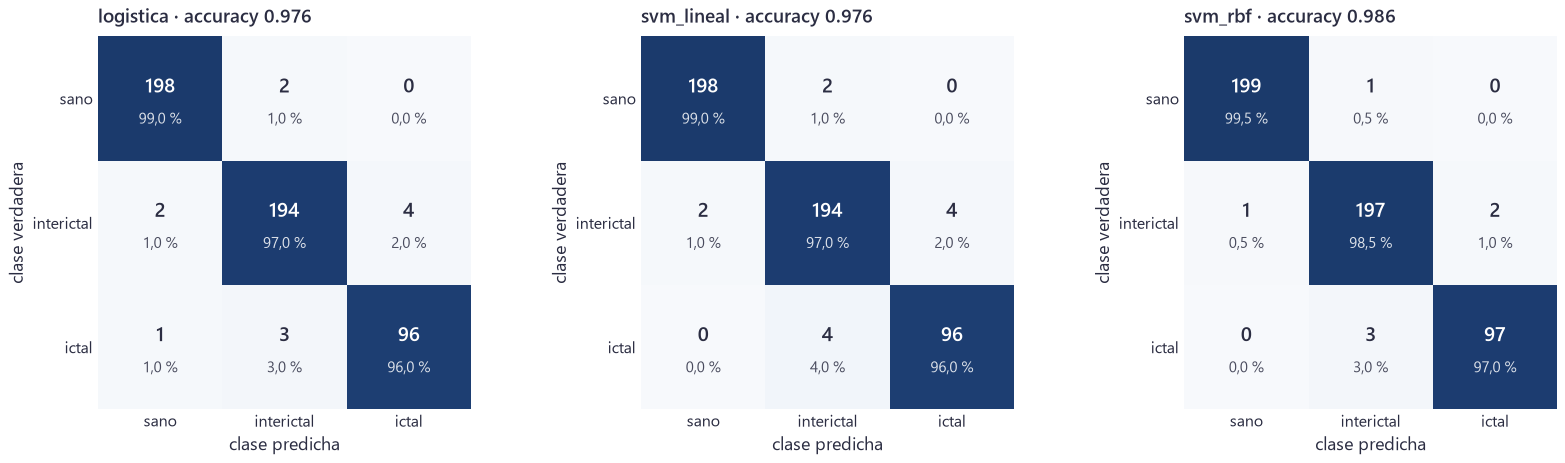

In [4]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
oof = {}
for nombre, modelo in MODELOS_BONN.items():
    metodo = "predict_proba" if nombre == "logistica" else "decision_function"
    oof[nombre] = cross_val_predict(modelo, Fb, y3, cv=cv10, method=metodo)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4))
filas = []
for ax, (nombre, s) in zip(ejes, oof.items()):
    pred = s.argmax(axis=1)
    cm = confusion_matrix(y3, pred)
    EG.matriz_confusion(ax, cm, CLASES, f"{nombre} · accuracy {accuracy_score(y3, pred):.3f}")
    for k, c in enumerate(CLASES):
        mv = M.metricas_ventana(y3 == k, pred == k)
        filas.append({"modelo": nombre, "clase": c, "sensibilidad": mv["sensibilidad"],
                      "especificidad": mv["especificidad"], "AUC_ovr": roc_auc_score(y3 == k, s[:, k])})
fig.tight_layout(); fig.savefig(SALIDA / "bonn_matrices_confusion.png")
tabla_bonn_clases = pd.DataFrame(filas).round(4)
tabla_bonn_clases.to_csv(SALIDA / "bonn_metricas_por_clase.csv", index=False)
tabla_bonn_clases

**Observaciones:** con solo 20 atributos de Fourier, un modelo lineal ya clasifica correctamente
cerca del 97 % de los segmentos; el SVM con núcleo RBF sube a 98 %. Los errores se concentran entre
**interictal** e **ictal**: algunos segmentos interictales del foco epileptógeno (set D) tienen
actividad parecida a una crisis.

### A.5 Curvas ROC (una clase contra el resto)

La curva ROC recorre todos los umbrales $\tau$ del puntaje $s(\mathbf{x})$ y grafica
$\big(\text{FPR}(\tau), \text{TPR}(\tau)\big) = \big(1 - \text{especificidad}, \text{sensibilidad}\big)$.
El área bajo la curva es la probabilidad de que un positivo elegido al azar tenga mayor puntaje que
un negativo elegido al azar:

$$\text{AUC} = P\big(s(\mathbf{x}^+) > s(\mathbf{x}^-)\big).$$

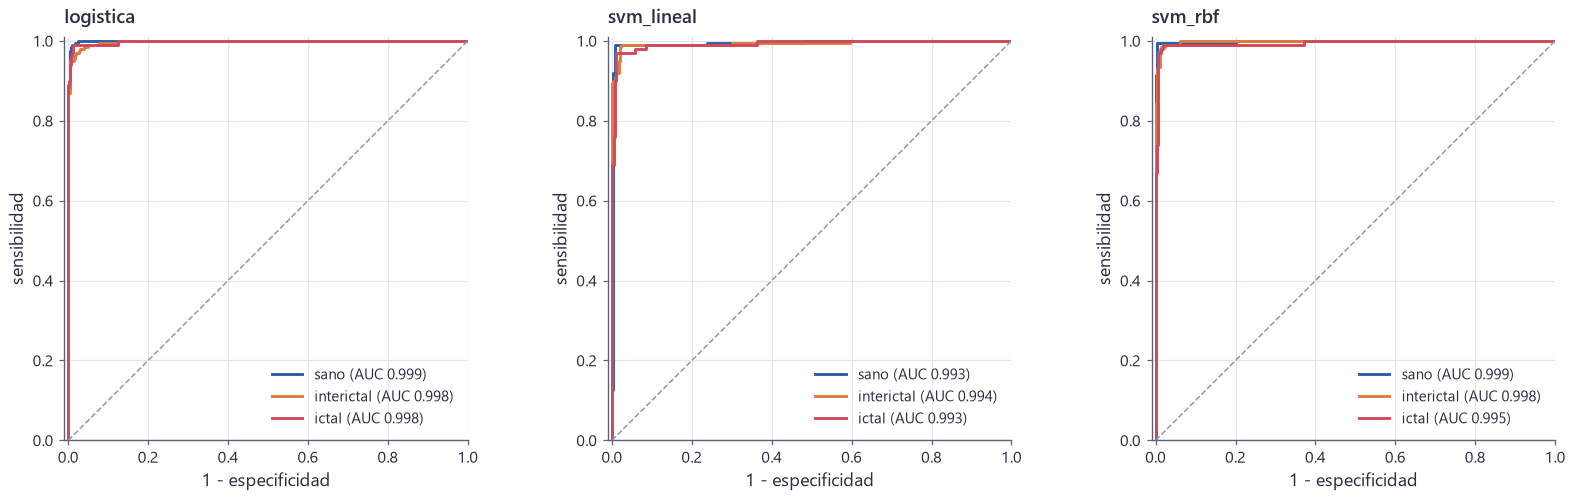

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (nombre, s) in zip(ejes, oof.items()):
    for k, c in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(y3 == k, s[:, k])
        ax.plot(fpr, tpr, color=EG.CLASES_BONN[k], label=f"{c} (AUC {roc_auc_score(y3 == k, s[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", c=EG.GRIS, lw=1)
    ax.set_xlim(-0.01, 1); ax.set_ylim(0, 1.01); ax.set_aspect("equal")
    ax.set_xlabel("1 - especificidad"); ax.set_ylabel("sensibilidad"); ax.set_title(nombre)
    ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "bonn_roc.png")

### A.6 Las probabilidades sobre el simplex

Cada segmento es un punto $\mathbf{p} = (p_\text{sano}, p_\text{interictal}, p_\text{ictal})$ del triángulo
$\Delta^2$. Los vértices son las predicciones con certeza total. La regla $\hat{y} = \arg\max_k p_k$
divide el triángulo en 3 regiones, separadas por los segmentos que van del baricentro
$(\tfrac13, \tfrac13, \tfrac13)$ al punto medio de cada lado (donde empatan dos clases).

Coordenadas en el plano: $u = p_1 + p_2/2$, $\ v = \tfrac{\sqrt{3}}{2} p_2$.

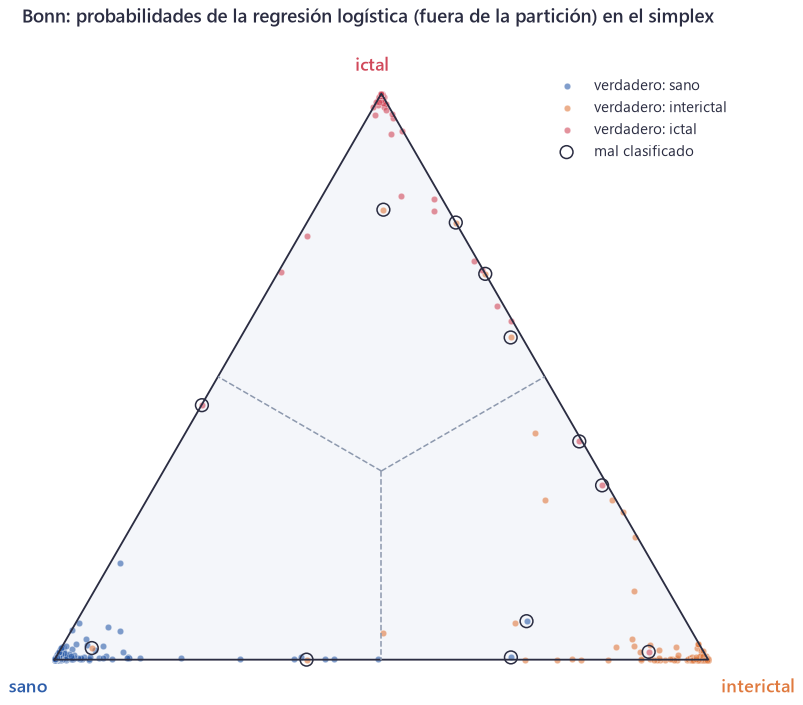

In [6]:
def a_plano(p):
    p = np.atleast_2d(p)
    return p[:, 1] + p[:, 2] / 2, p[:, 2] * np.sqrt(3) / 2

P_oof = oof["logistica"]
fig, ax = plt.subplots(figsize=(7.5, 6.8))
vert = np.eye(3)
u, v = a_plano(np.vstack([vert, vert[:1]]))
ax.fill(u, v, color="#F4F6FA", zorder=0)
ax.plot(u, v, "-", c=EG.TINTA, lw=1.2)
centro = np.full((1, 3), 1 / 3)
for i, j in [(0, 1), (1, 2), (0, 2)]:
    medio = (vert[i] + vert[j]) / 2
    uu, vv = a_plano(np.vstack([centro, medio]))
    ax.plot(uu, vv, "--", c=EG.GRIS, lw=1)
colores = EG.CLASES_BONN
for k, c in enumerate(CLASES):
    u, v = a_plano(P_oof[y3 == k])
    ax.scatter(u, v, s=18, alpha=0.6, c=colores[k], edgecolors="white", linewidths=0.3, label=f"verdadero: {c}")
mal = P_oof.argmax(1) != y3
u, v = a_plano(P_oof[mal])
ax.scatter(u, v, s=70, facecolors="none", edgecolors=EG.TINTA, lw=1, label="mal clasificado")
for k, (du, dv) in enumerate([(-0.07, -0.05), (0.02, -0.05), (-0.04, 0.035)]):
    u, v = a_plano(vert[k])
    ax.text(u[0] + du, v[0] + dv, CLASES[k], fontsize=12, fontweight="semibold", color=colores[k])
ax.set_aspect("equal"); ax.axis("off"); ax.legend(loc="upper right")
ax.set_title("Bonn: probabilidades de la regresión logística (fuera de la partición) en el simplex", pad=28)
fig.tight_layout(); fig.savefig(SALIDA / "bonn_simplex.png")

**Observaciones:** casi todos los segmentos quedan pegados a su vértice (predicción con alta certeza).
Los errores están sobre el **lado ictal–interictal** del triángulo: el modelo casi nunca confunde un
segmento sano con uno ictal, pero sí duda entre interictal e ictal (probabilidad de "sano" ≈ 0).
Varios segmentos sanos caen sobre el lado sano–interictal, consistentes con que el set B (ojos
cerrados) tiene mucha potencia alfa y se parece a algunos registros intracraneales.

### A.7 ¿Qué frecuencias usa el modelo?

Con atributos estandarizados, el coeficiente $w_{k,j}$ indica cuánto aumenta el puntaje de la clase $k$
cuando la log-potencia de la banda $j$ sube un desvío estándar.

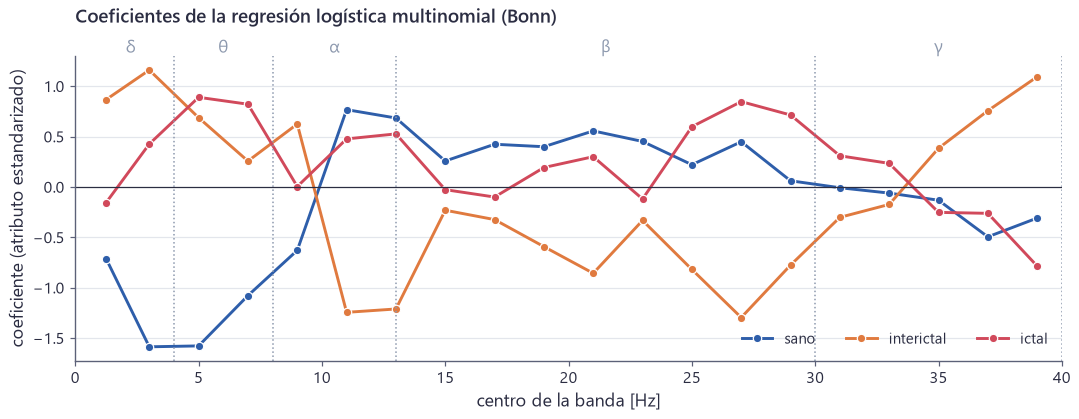

In [7]:
logit = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(Fb, y3)
W = logit[-1].coef_
fig, ax = plt.subplots(figsize=(10, 4))
for k, c in enumerate(CLASES):
    ax.plot(CENTROS, W[k], "o-", color=colores[k], label=c, markeredgecolor="white", markeredgewidth=0.8)
ax.axhline(0, c=EG.TINTA, lw=0.8)
for lim, (lo, nombre_b) in zip([4, 8, 13, 30, 40], [(0.5, "δ"), (4, "θ"), (8, "α"), (13, "β"), (30, "γ")]):
    ax.axvline(lim, c=EG.GRIS, ls=":", lw=1)
    ax.text((lo + lim) / 2, 1.0, nombre_b, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=11, color=EG.GRIS)
ax.set_xlim(0, 40); ax.grid(axis="x", visible=False)
ax.set_xlabel("centro de la banda [Hz]"); ax.set_ylabel("coeficiente (atributo estandarizado)")
ax.set_title("Coeficientes de la regresión logística multinomial (Bonn)", pad=22); ax.legend(ncol=3, loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "bonn_coeficientes.png")
pd.DataFrame(W, index=CLASES, columns=[f"{lo:g}-{hi:g}Hz" for lo, hi in zip(BORDES[:-1], BORDES[1:])]).round(2).to_csv(
    SALIDA / "bonn_coeficientes.csv")

## Parte B — Optimalidad local y global

### B.1 Por qué la regresión logística tiene un único óptimo

Caso binario (ictal contra el resto), con $\boldsymbol\theta = (\mathbf{w}, b)$,
$\sigma(z) = 1/(1 + e^{-z})$ y $p_i = \sigma(\boldsymbol\theta^\top \tilde{\mathbf{x}}_i)$:

$$J(\boldsymbol\theta) = \frac{1}{n}\sum_{i=1}^{n}\Big[\log\big(1 + e^{\boldsymbol\theta^\top\tilde{\mathbf{x}}_i}\big) - y_i\,\boldsymbol\theta^\top\tilde{\mathbf{x}}_i\Big] + \frac{\lambda}{2}\lVert \mathbf{w} \rVert^2$$

$$\nabla J = \frac{1}{n}\tilde X^\top(\mathbf{p} - \mathbf{y}) + \lambda \begin{pmatrix}\mathbf{w}\\0\end{pmatrix}, \qquad
\nabla^2 J = \frac{1}{n}\tilde X^\top S\, \tilde X + \lambda \begin{pmatrix}I & 0\\ 0 & 0\end{pmatrix}, \quad S = \operatorname{diag}\big(p_i(1-p_i)\big).$$

Como $0 < p_i(1 - p_i) \le \tfrac14$, para todo $\mathbf{v} \neq 0$:
$\mathbf{v}^\top \nabla^2 J\, \mathbf{v} = \tfrac1n \lVert S^{1/2}\tilde X \mathbf{v}\rVert^2 + \lambda\lVert \mathbf{v}_w\rVert^2 > 0$
(si $\tilde X$ tiene rango completo). La Hessiana es **definida positiva**, $J$ es **estrictamente convexa**
y todo mínimo local es **el** mínimo global. Además $\nabla J$ es Lipschitz con constante
$L \le \tfrac{1}{4n}\lambda_{\max}(\tilde X^\top \tilde X) + \lambda$, así que el descenso por gradiente con paso
$\eta = 1/L$ converge desde cualquier punto inicial.

### B.2 Experimento: 20 inicializaciones al azar

In [8]:
yb = (y3 == 2).astype(float)
Xs = StandardScaler().fit_transform(Fb)
n = len(yb)
Xa = np.hstack([Xs, np.ones((n, 1))])
LAM = 1e-2

def J(th):
    z = Xa @ th
    return np.mean(np.logaddexp(0, z) - yb * z) + LAM / 2 * np.sum(th[:-1] ** 2)

def grad(th):
    g = Xa.T @ (expit(Xa @ th) - yb) / n
    g[:-1] += LAM * th[:-1]
    return g

L = np.linalg.eigvalsh(Xa.T @ Xa / n).max() / 4 + LAM
eta = 1 / L
ref = LogisticRegression(C=1 / (LAM * n), tol=1e-12, max_iter=100000).fit(Xs, yb)
th_ref = np.concatenate([ref.coef_.ravel(), ref.intercept_])
J_ref = J(th_ref)

rng = np.random.default_rng(SEMILLA)
ITER = 20000
curvas, finales = [], []
for s in range(20):
    th = rng.normal(0, 3, size=Xa.shape[1])
    hist = []
    for it in range(ITER):
        if it % 50 == 0:
            hist.append(J(th) - J_ref)
        th -= eta * grad(th)
    curvas.append(hist); finales.append(th)
finales = np.array(finales)
dist = np.linalg.norm(finales - th_ref, axis=1)
print(f"L = {L:.3f}, paso = {eta:.4f}")
print(f"J(θ*) de sklearn = {J_ref:.8f}")
print(f"J final, 20 inicios: min {min(J(t) for t in finales):.8f}  max {max(J(t) for t in finales):.8f}")
print(f"||θ_final - θ*||: max {dist.max():.2e}   (distancia inicial media {np.linalg.norm(rng.normal(0, 3, (20, Xa.shape[1])), axis=1).mean():.1f})")

L = 4.298, paso = 0.2327
J(θ*) de sklearn = 0.07699786
J final, 20 inicios: min 0.07699786  max 0.07699786
||θ_final - θ*||: max 2.99e-07   (distancia inicial media 13.2)


### B.3 Contraste: una red neuronal chica no es convexa

Perceptrón multicapa con una capa oculta $\tanh$, entrenado hasta convergencia (L-BFGS) desde 20 semillas.
La pérdida $J(\boldsymbol\theta)$ ya no es convexa, por dos motivos distintos:

1. **Simetrías.** Permutar las neuronas ocultas, o cambiar el signo de los pesos de entrada y de salida
   de una neurona ($\tanh$ es impar), no cambia la función. Con $h$ neuronas hay $h!\,2^h$ copias de
   cada mínimo. Son mínimos **equivalentes**: misma pérdida, pesos distintos. Si $J$ fuera convexa,
   el conjunto de mínimos sería convexo y el punto medio entre dos de ellos también sería mínimo; no lo es.
2. **Mínimos locales genuinos**, con pérdida distinta, donde el descenso por gradiente queda atrapado.

Experimento (a): ictal contra el resto, 4 neuronas, $\alpha = 1$ (misma tarea que B.2).
Experimento (b): 3 clases, 2 neuronas, $\alpha = 10^{-3}$.

(a) ictal vs resto, 4 neuronas, alpha=1
    pérdida final: min 0.041217 max 0.041217 -> 1 valor(es) distinto(s)
    distancia entre los pesos de la semilla 6 y la 14: 9.70
    pérdida en el punto medio entre ambas: 0.596001 (> 0.041217: J no es convexa)
(b) 3 clases, 2 neuronas, alpha=1e-3
    pérdida final: min 0.00099 max 0.01983 -> 8 mínimos distintos
    por semilla: [0.00099 0.00103 0.00103 0.00105 0.0013  0.00141 0.00159 0.00178 0.00178
 0.00182 0.01135 0.01135 0.01135 0.01135 0.01135 0.01135 0.01135 0.01135
 0.01135 0.01983]


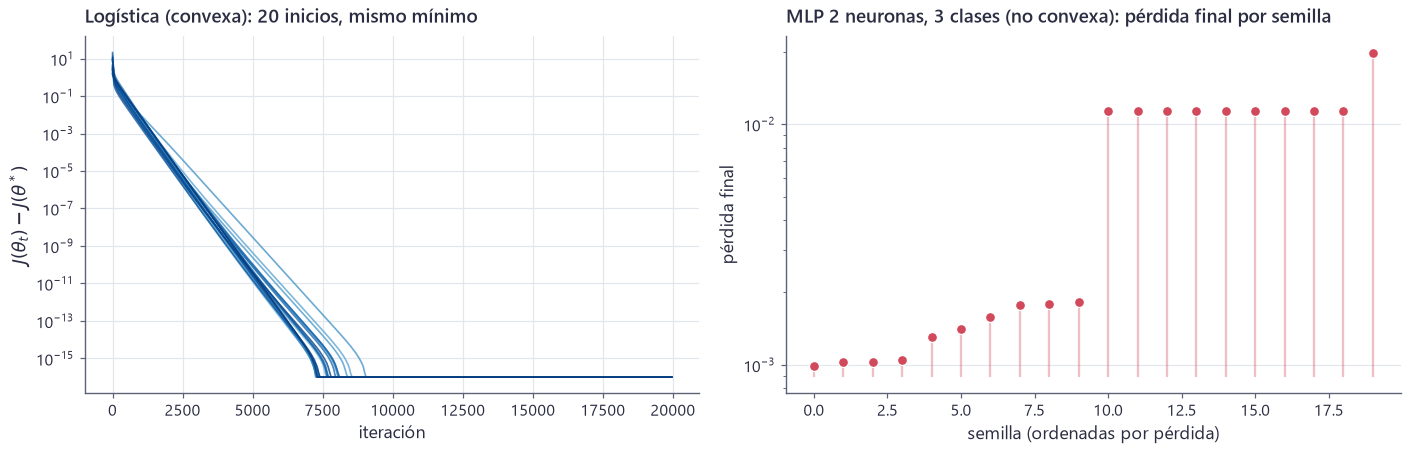

In [9]:
def correr_mlp(y, h, alpha, semillas=20):
    perd, pesos, modelos = [], [], []
    for s in range(semillas):
        mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="tanh", solver="lbfgs", alpha=alpha,
                            max_iter=20000, tol=1e-10, random_state=s).fit(Xs, y)
        perd.append(mlp.loss_); modelos.append(mlp)
        pesos.append(np.concatenate([w.ravel() for w in mlp.coefs_ + mlp.intercepts_]))
    return np.array(perd), np.array(pesos), modelos

perd_a, pesos_a, mod_a = correr_mlp(yb, 4, 1.0)
perd_b, pesos_b, _ = correr_mlp(y3, 2, 1e-3)

# Punto medio entre dos soluciones del experimento (a) con la misma pérdida pero pesos distintos
i0 = int(np.argmin(perd_a))
i1 = int(np.argmax(np.linalg.norm(pesos_a - pesos_a[i0], axis=1)))
def perdida_mlp(coefs, inter, alpha=1.0):
    """Misma función objetivo que minimiza sklearn: log-loss + alpha/(2n) * suma de pesos al cuadrado."""
    z = np.tanh(Xs @ coefs[0] + inter[0]) @ coefs[1] + inter[1]
    z = z.ravel()
    return np.mean(np.logaddexp(0, z) - yb * z) + alpha * sum((w ** 2).sum() for w in coefs) / (2 * len(yb))

J_i0 = perdida_mlp(mod_a[i0].coefs_, mod_a[i0].intercepts_)
assert abs(J_i0 - perd_a[i0]) < 1e-6
J_med = perdida_mlp([(a + b) / 2 for a, b in zip(mod_a[i0].coefs_, mod_a[i1].coefs_)],
                    [(a + b) / 2 for a, b in zip(mod_a[i0].intercepts_, mod_a[i1].intercepts_)])

print("(a) ictal vs resto, 4 neuronas, alpha=1")
print(f"    pérdida final: min {perd_a.min():.6f} max {perd_a.max():.6f} -> {len(np.unique(perd_a.round(5)))} valor(es) distinto(s)")
print(f"    distancia entre los pesos de la semilla {i0} y la {i1}: {np.linalg.norm(pesos_a[i1] - pesos_a[i0]):.2f}")
print(f"    pérdida en el punto medio entre ambas: {J_med:.6f} (> {perd_a[i0]:.6f}: J no es convexa)")
print("(b) 3 clases, 2 neuronas, alpha=1e-3")
print(f"    pérdida final: min {perd_b.min():.5f} max {perd_b.max():.5f} -> {len(np.unique(perd_b.round(4)))} mínimos distintos")
print("    por semilla:", np.round(np.sort(perd_b), 5))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.3))
it = np.arange(0, ITER, 50)
for h, col in zip(curvas, plt.cm.Blues(np.linspace(0.45, 0.95, len(curvas)))):
    ejes[0].semilogy(it, np.maximum(h, 1e-16), lw=1.1, alpha=0.8, color=col)
ejes[0].set_xlabel("iteración"); ejes[0].set_ylabel(r"$J(\theta_t) - J(\theta^*)$")
ejes[0].set_title("Logística (convexa): 20 inicios, mismo mínimo")
orden_b = np.sort(perd_b)
ejes[1].vlines(np.arange(20), orden_b.min() * 0.9, orden_b, color=EG.ROJO, alpha=0.35, lw=1.5)
ejes[1].scatter(np.arange(20), orden_b, c=EG.ROJO, s=42, edgecolors="white", linewidths=0.8, zorder=3)
ejes[1].set_yscale("log"); ejes[1].grid(axis="x", visible=False)
ejes[1].set_xlabel("semilla (ordenadas por pérdida)"); ejes[1].set_ylabel("pérdida final")
ejes[1].set_title("MLP 2 neuronas, 3 clases (no convexa): pérdida final por semilla")
fig.tight_layout(); fig.savefig(SALIDA / "optimalidad_convexo_vs_no_convexo.png")

**Observaciones:**
- **Logística (convexa):** las 20 corridas, desde puntos iniciales a distancia ≈ 13 del óptimo, llegan
  todas al mismo $\boldsymbol\theta^*$ (diferencia en los parámetros $< 10^{-6}$) y la brecha
  $J(\boldsymbol\theta_t) - J^*$ cae en forma **lineal en escala logarítmica**, que es la
  convergencia geométrica que garantiza la convexidad fuerte (aporta el término $\lambda$).
  La curva se aplana en $10^{-16}$ por la precisión de punto flotante.
- **MLP (no convexa), experimento (a):** las 20 semillas terminan con la misma pérdida pero con pesos
  muy distintos; en el **punto medio** entre dos soluciones la pérdida sube de 0,041 a 0,596. En una
  función convexa eso es imposible: son mínimos equivalentes por simetría.
- **MLP, experimento (b):** con 3 clases y solo 2 neuronas aparecen **8 valores distintos** de la pérdida
  final, que varían en un factor 20. Casi la mitad de las semillas queda atrapada en el mismo mínimo
  local (pérdida 0,011), diez veces peor que el mejor. Por eso, en la etapa de la CNN, cada optimizador
  se corre con varias semillas.

## Parte C — Multiplicadores de Lagrange en el SVM

### C.1 Primal, Lagrangiano y dual

Con etiquetas $y_i \in \{-1, +1\}$, el SVM de margen blando resuelve

$$\min_{\mathbf{w}, b, \boldsymbol\xi}\ \frac12 \lVert\mathbf{w}\rVert^2 + C\sum_i \xi_i
\quad\text{s.a.}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b) \ge 1 - \xi_i,\quad \xi_i \ge 0.$$

Con multiplicadores $\alpha_i \ge 0$ y $\mu_i \ge 0$:

$$\mathcal{L} = \frac12\lVert\mathbf{w}\rVert^2 + C\sum_i\xi_i - \sum_i \alpha_i\big[y_i(\mathbf{w}^\top\mathbf{x}_i + b) - 1 + \xi_i\big] - \sum_i\mu_i\xi_i.$$

Anulando las derivadas:
$\ \partial_{\mathbf{w}}\mathcal{L} = 0 \Rightarrow \mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$,
$\ \partial_b\mathcal{L} = 0 \Rightarrow \sum_i \alpha_i y_i = 0$,
$\ \partial_{\xi_i}\mathcal{L} = 0 \Rightarrow \alpha_i = C - \mu_i \Rightarrow 0 \le \alpha_i \le C$.
Reemplazando se obtiene el **dual**:

$$\max_{\boldsymbol\alpha}\ \sum_i\alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\, \mathbf{x}_i^\top\mathbf{x}_j
\quad\text{s.a.}\quad 0 \le \alpha_i \le C,\quad \sum_i\alpha_i y_i = 0.$$

El problema es convexo y cumple la condición de Slater, así que hay **dualidad fuerte**: el valor
óptimo del primal y del dual coinciden. Las condiciones de **KKT** (holgura complementaria) dicen:

| $\alpha_i$ | Condición sobre $m_i = y_i f(\mathbf{x}_i)$ | Interpretación |
|---|---|---|
| $\alpha_i = 0$ | $m_i \ge 1$ | bien clasificado, fuera del margen: no influye en $\mathbf{w}$ |
| $0 < \alpha_i < C$ | $m_i = 1$ | vector soporte sobre el margen |
| $\alpha_i = C$ | $m_i \le 1$ | dentro del margen o mal clasificado ($\xi_i = 1 - m_i$) |

El dual solo depende de productos internos $\mathbf{x}_i^\top\mathbf{x}_j$: reemplazándolos por un núcleo
$k(\mathbf{x}_i, \mathbf{x}_j)$ se obtiene el SVM con kernel RBF de la Parte A.

### C.2 Verificación numérica: ictal (E) contra interictal epileptógeno (D)

In [10]:
mk = np.isin(set_b, ["D", "E"])
Xk = StandardScaler().fit_transform(Fb[mk])
yk = np.where(set_b[mk] == "E", 1.0, -1.0)
CSVM = 1.0
svm = SVC(kernel="linear", C=CSVM, tol=1e-8).fit(Xk, yk)
ay = svm.dual_coef_.ravel()          # alpha_i * y_i de los vectores soporte
sv = svm.support_
alfa = np.zeros(len(yk)); alfa[sv] = np.abs(ay)
w = ay @ Xk[sv]
b = svm.intercept_[0]
m = yk * (Xk @ w + b)
eps = 1e-6 * CSVM
libre = (alfa > eps) & (alfa < CSVM - eps)
acot = alfa >= CSVM - eps
cero = alfa <= eps
primal = 0.5 * w @ w + CSVM * np.maximum(0, 1 - m).sum()
dual = alfa.sum() - 0.5 * w @ w

kkt = pd.DataFrame([
    ("signo de alfa_i*y_i coincide con y_i", bool(np.all(np.sign(ay) == yk[sv]))),
    ("w = sum alfa_i y_i x_i coincide con coef_", float(np.abs(w - svm.coef_.ravel()).max())),
    ("sum alfa_i y_i (debe ser 0)", float(ay.sum())),
    ("min alfa / max alfa (entre 0 y C)", f"{alfa.min():.3g} / {alfa.max():.6g}"),
    ("alfa = 0: cantidad, min m_i (>= 1)", f"{cero.sum()}, {m[cero].min():.4f}"),
    ("0 < alfa < C: cantidad, m_i (= 1)", f"{libre.sum()}, [{m[libre].min():.4f}, {m[libre].max():.4f}]"),
    ("alfa = C: cantidad, max m_i (<= 1)", f"{acot.sum()}, {m[acot].max():.4f}"),
    ("valor primal", f"{primal:.6f}"),
    ("valor dual", f"{dual:.6f}"),
    ("brecha de dualidad relativa", f"{(primal - dual) / primal:.2e}"),
], columns=["verificación", "valor"])
kkt.to_csv(SALIDA / "svm_kkt.csv", index=False)
kkt

,verificación,valor
0,signo de alfa_i*y_i coincide con y_i,True
1,w = sum alfa_i y_i x_i coincide con coef_,0.0
2,sum alfa_i y_i (debe ser 0),-0.0
3,min alfa / max alfa (entre 0 y C),0 / 1
4,"alfa = 0: cantidad, min m_i (>= 1)","180, 1.0127"
5,"0 < alfa < C: cantidad, m_i (= 1)","9, [1.0000, 1.0000]"
6,"alfa = C: cantidad, max m_i (<= 1)","11, 0.6293"
7,valor primal,11.692841
8,valor dual,11.692839
9,brecha de dualidad relativa,1.55e-07


**Observaciones:** las condiciones de KKT se cumplen a la precisión numérica. De 200 segmentos, solo
20 tienen $\alpha_i > 0$ (vectores soporte): el hiperplano queda determinado por esos 20 puntos y los
otros 180 se podrían borrar sin cambiar la solución. Los valores del primal y del dual coinciden
(dualidad fuerte).

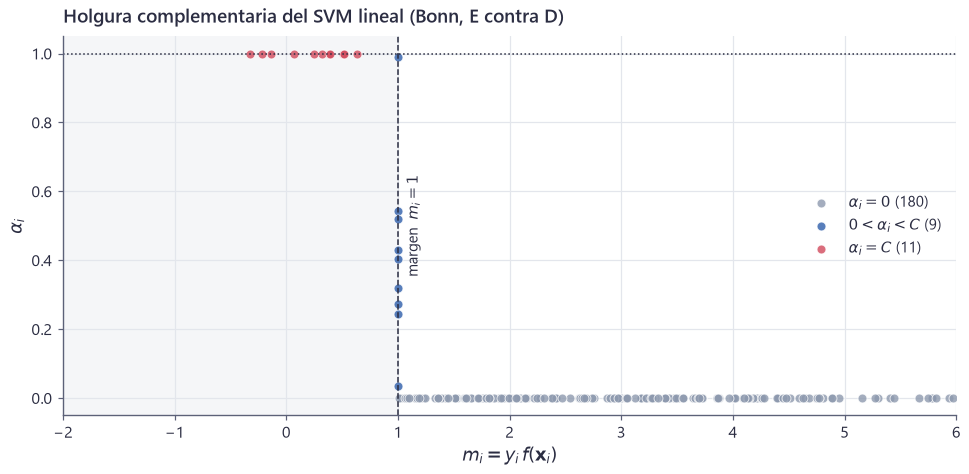

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(-2, 1, color=EG.GRIS_CLARO, alpha=0.35, lw=0)
for msk, c, et in [(cero, EG.GRIS, r"$\alpha_i = 0$"), (libre, EG.AZUL, r"$0<\alpha_i<C$"), (acot, EG.ROJO, r"$\alpha_i = C$")]:
    ax.scatter(m[msk], alfa[msk], s=34, c=c, alpha=0.8, edgecolors="white", linewidths=0.6, label=f"{et} ({msk.sum()})")
ax.axvline(1, c=EG.TINTA, ls="--", lw=1); ax.axhline(CSVM, c=EG.TINTA, ls=":", lw=1)
ax.text(1.08, 0.5, "margen  $m_i = 1$", transform=ax.get_xaxis_transform(), fontsize=9.5, color=EG.TINTA, rotation=90, va="center")
ax.set_xlabel(r"$m_i = y_i\,f(\mathbf{x}_i)$"); ax.set_ylabel(r"$\alpha_i$"); ax.set_xlim(-2, 6)
ax.set_title("Holgura complementaria del SVM lineal (Bonn, E contra D)"); ax.legend(loc="center right")
fig.tight_layout(); fig.savefig(SALIDA / "svm_kkt.png")

## Parte D — CHB-MIT: detección en un paciente que el modelo nunca vio

### D.1 Umbral de Neyman-Pearson

En un monitor de crisis, lo que se fija es cuántas falsas alarmas se toleran. Con un puntaje $s(\mathbf{x})$
y un umbral $\tau$:

$$P_D(\tau) = P(s > \tau \mid \text{crisis}), \qquad P_{FA}(\tau) = P(s > \tau \mid \text{sin crisis}).$$

**Problema:** $\max_\tau P_D(\tau)$ sujeto a $P_{FA}(\tau) \le \alpha$. Lagrangiano:

$$\mathcal{L}(\tau, \lambda) = P_D(\tau) - \lambda\big(P_{FA}(\tau) - \alpha\big), \quad \lambda \ge 0.$$

Con densidades $p_1, p_0$ del puntaje en cada clase, $\partial_\tau P_D = -p_1(\tau)$ y
$\partial_\tau P_{FA} = -p_0(\tau)$, así que la condición de estacionariedad es

$$\frac{p_1(\tau)}{p_0(\tau)} = \lambda,$$

que es el **lema de Neyman-Pearson**: el detector óptimo compara la razón de verosimilitud con un umbral.
Como $P_D$ crece cuando $\tau$ baja, la restricción está activa ($\lambda > 0$, holgura complementaria) y
$\tau^*$ es el cuantil $1-\alpha$ del puntaje en la clase negativa. La salida de la regresión logística es
$\log\frac{p_1(\mathbf{x})}{p_0(\mathbf{x})} + \text{cte}$, una función creciente de la razón de verosimilitud,
así que umbralizarla es equivalente.

Con ventanas de 4 s hay 900 ventanas por hora; se usa $\alpha = 10^{-3}$, del orden de
**una ventana falsa por hora**. El umbral se calcula con las ventanas sin crisis de los pacientes de
**entrenamiento** (el de prueba no se usa para nada).

### D.2 Post-procesamiento y evaluación por evento

El puntaje se suaviza con la media de las últimas 3 ventanas (12 s, causal: solo usa el pasado).
Además de las métricas por ventana se informa lo que importa en la clínica:

- **Sensibilidad por evento:** fracción de crisis con al menos una ventana positiva.
- **Falsas alarmas por hora:** rachas de ventanas positivas que no tocan ninguna crisis, por hora sin crisis.
- **Latencia:** desde el inicio anotado hasta el final de la primera ventana positiva.

### D.3 Dos variantes de atributos

1. **global:** log-potencia de 18 canales × 5 bandas (90 atributos), estandarizada con el entrenamiento.
2. **calibrado:** a cada paciente se le resta la mediana de sus propios atributos (todas sus ventanas,
   sin etiquetas). Es una calibración no supervisada del nivel basal; en la Etapa 2 se vio que el nivel
   basal cambia mucho de un paciente a otro. En la práctica equivale a grabar un rato al paciente nuevo
   antes de usar el detector.

In [12]:
Z = np.load(RAIZ / "datos" / "chbmit_proc" / "chbmit_bandas.npz")
Xc = Z["bp"].reshape(len(Z["bp"]), -1)
ictal, borde, t0 = Z["ictal"].astype(bool), Z["borde"].astype(bool), Z["t0"]
pac, arch = Z["paciente"], Z["archivo"]
crisis = pd.read_csv(RAIZ / "datos" / "chbmit_proc" / "crisis.csv")
PACIENTES = sorted(np.unique(pac))

Xcal = Xc.copy()
for p in PACIENTES:
    Xcal[pac == p] -= np.median(Xc[pac == p], axis=0)
VARIANTES = {"global": Xc, "calibrado": Xcal}

def nuevos_modelos():
    return {"logistica": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)),
            "svm_lineal": make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced", dual=False, max_iter=10000))}

ALFA_NP = 1e-3
K_SUAVE = 3
print(Xc.shape, "| ventanas ictales:", ictal.sum(), "| pacientes:", PACIENTES)

(200563, 90) | ventanas ictales: 711 | pacientes: [np.str_('chb01'), np.str_('chb02'), np.str_('chb03'), np.str_('chb05'), np.str_('chb08'), np.str_('chb10')]


In [13]:
def evaluar(s_te, te, umbral):
    limpio = te & ~borde
    pred = s_te > umbral
    mv = M.metricas_ventana(ictal[limpio], pred[limpio[te]])
    ev, det = M.evaluar_eventos(arch[te], t0[te], pred, crisis)
    return mv, ev, det

filas, scores, detecciones = [], {}, []
t_ini = time.time()
for var, F in VARIANTES.items():
    for p in PACIENTES:
        te = pac == p
        tr = ~te
        for nombre, modelo in nuevos_modelos().items():
            modelo.fit(F[tr & ~borde], ictal[tr & ~borde])
            s_tr = M.suavizar(modelo.decision_function(F[tr]), arch[tr], K_SUAVE)
            s_te = M.suavizar(modelo.decision_function(F[te]), arch[te], K_SUAVE)
            neg_tr = ~ictal[tr] & ~borde[tr]
            tau = M.umbral_neyman_pearson(s_tr[neg_tr], ALFA_NP)
            scores[(var, nombre, p)] = s_te
            limpio = ~borde[te]
            auc = roc_auc_score(ictal[te][limpio], s_te[limpio])
            for regla, umbral in [("neyman_pearson", tau), ("cero", 0.0)]:
                mv, ev, det = evaluar(s_te, te, umbral)
                filas.append({"variante": var, "modelo": nombre, "paciente": p, "regla": regla, "umbral": umbral,
                              "AUC": auc, **mv, **ev})
                if regla == "neyman_pearson":
                    detecciones.append(det.assign(variante=var, modelo=nombre, paciente=p))
print(f"LOPO terminado en {time.time() - t_ini:.0f} s")
lopo = pd.DataFrame(filas)
lopo.to_csv(SALIDA / "chbmit_lopo_detalle.csv", index=False)
pd.concat(detecciones).to_csv(SALIDA / "chbmit_lopo_eventos.csv", index=False)

LOPO terminado en 86 s


### D.4 Resultados por paciente (regresión logística, umbral de Neyman-Pearson)

In [14]:
cols = ["paciente", "AUC", "sensibilidad", "especificidad", "crisis", "detectadas", "FA_por_hora", "latencia_mediana_s"]
for var in VARIANTES:
    print(f"--- variante {var}")
    t = lopo.query("variante == @var and modelo == 'logistica' and regla == 'neyman_pearson'")[cols].round(3)
    print(t.to_string(index=False))

--- variante global
paciente   AUC  sensibilidad  especificidad  crisis  detectadas  FA_por_hora  latencia_mediana_s
   chb01 0.971         0.056          1.000       7           2        0.099                41.0
   chb02 0.956         0.049          0.997       3           1        1.221                72.0
   chb03 0.949         0.104          0.992       7           3        1.901                22.0
   chb05 0.980         0.853          0.992       5           5        2.652                18.0
   chb08 0.835         0.288          0.997       5           5        1.975                18.0
   chb10 0.986         0.829          0.985       7           7        4.109                 7.0
--- variante calibrado
paciente   AUC  sensibilidad  especificidad  crisis  detectadas  FA_por_hora  latencia_mediana_s
   chb01 0.982         0.196          1.000       7           3        0.000                32.0
   chb02 0.978         0.049          0.999       3           1        0.085        

### D.5 Resumen: promedio entre los 6 pacientes de prueba

In [15]:
def resumir(df):
    g = df.groupby(["variante", "modelo", "regla"])
    r = g.agg(AUC=("AUC", "mean"), AUC_desvio=("AUC", "std"), sens_ventana=("sensibilidad", "mean"),
              espec_ventana=("especificidad", "mean"), crisis=("crisis", "sum"), detectadas=("detectadas", "sum"),
              falsas_alarmas=("falsas_alarmas", "sum"), horas=("horas_sin_crisis", "sum"),
              latencia_mediana_s=("latencia_mediana_s", "median"))
    r["sens_eventos"] = r.detectadas / r.crisis
    r["FA_por_hora"] = r.falsas_alarmas / r.horas
    return r.drop(columns=["horas"]).round(4).reset_index()

resumen_lopo = resumir(lopo)
resumen_lopo.to_csv(SALIDA / "chbmit_lopo_resumen.csv", index=False)
resumen_lopo

,variante,modelo,regla,AUC,AUC_desvio,sens_ventana,espec_ventana,crisis,detectadas,falsas_alarmas,latencia_mediana_s,sens_eventos,FA_por_hora
0,calibrado,logistica,cero,0.9493,0.0599,0.7792,0.9549,34,34,2443,12.50,1.0000,11.0043
1,calibrado,logistica,neyman_pearson,0.9493,0.0599,0.3343,0.9937,34,24,254,25.25,0.7059,1.1441
2,calibrado,svm_lineal,cero,0.9479,0.0592,0.7721,0.9532,34,34,2508,12.50,1.0000,11.2971
3,calibrado,svm_lineal,neyman_pearson,0.9479,0.0592,0.3337,0.9937,34,24,266,22.25,0.7059,1.1982
4,global,logistica,cero,0.9462,0.0561,0.6270,0.8930,34,28,3802,12.25,0.8235,17.1259
5,global,logistica,neyman_pearson,0.9462,0.0561,0.3630,0.9939,34,23,466,20.00,0.6765,2.0991
6,global,svm_lineal,cero,0.9440,0.0544,0.6246,0.8899,34,28,3825,12.25,0.8235,17.2295
7,global,svm_lineal,neyman_pearson,0.9440,0.0544,0.3519,0.9937,34,24,484,20.00,0.7059,2.1801


**Observaciones:**
- **El AUC por ventana (~0,95) es engañoso.** Con 280 ventanas normales por cada ventana con crisis,
  una especificidad de 95 % ya son 45 ventanas falsas por hora. Con el umbral "natural" (puntaje 0,
  o sea $p = 0{,}5$ con clases balanceadas) se detectan todas las crisis pero con **11 a 17 falsas
  alarmas por hora**: inservible en la clínica.
- **El umbral de Neyman-Pearson** baja las falsas alarmas a 1–2 por hora a cambio de detectar
  alrededor del 70 % de las crisis. Es el compromiso sensibilidad–especificidad hecho explícito con
  un multiplicador de Lagrange.
- **La restricción no se cumple igual en todos los pacientes**: el umbral se fija con los pacientes
  de entrenamiento, y en el paciente nuevo la tasa de falsas alarmas sale entre 0 y 4,6 por hora.
  El supuesto de Neyman-Pearson (que la distribución del puntaje sin crisis es la misma en
  entrenamiento y en uso) no vale entre pacientes.
- **Calibrar el nivel basal del paciente** (restar su mediana) baja las falsas alarmas a casi la
  mitad con la misma sensibilidad por evento. Confirma lo visto en la Etapa 2: buena parte de la
  dificultad es la diferencia de nivel entre pacientes.
- Los dos modelos (logística y SVM lineal) dan resultados casi idénticos: ambos son clasificadores
  lineales sobre los mismos atributos, solo cambia la pérdida (logística contra bisagra).

### D.6 Curvas ROC por paciente de prueba

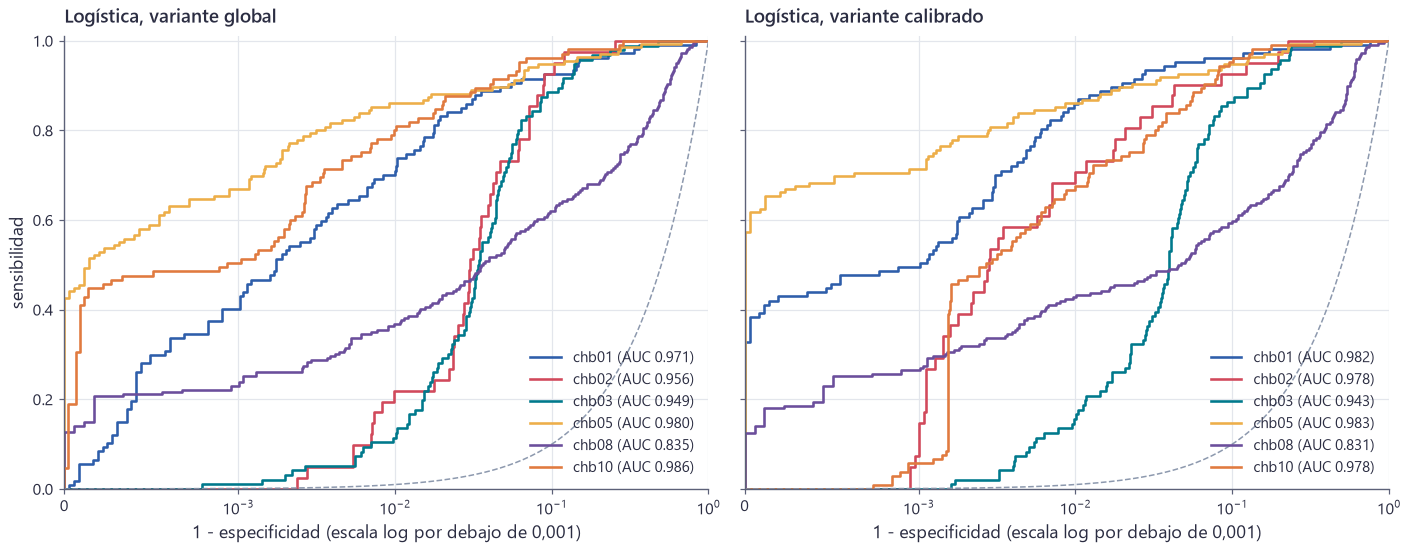

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, var in zip(ejes, VARIANTES):
    for p, col in zip(PACIENTES, EG.CICLO):
        te = pac == p
        limpio = ~borde[te]
        s = scores[(var, "logistica", p)][limpio]
        fpr, tpr, _ = roc_curve(ictal[te][limpio], s)
        ax.plot(fpr, tpr, lw=1.7, color=col, label=f"{p} (AUC {roc_auc_score(ictal[te][limpio], s):.3f})")
    azar = np.concatenate([[0], np.logspace(-5, 0, 200)])
    ax.plot(azar, azar, ls="--", c=EG.GRIS, lw=1)
    ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax.set_xlabel("1 - especificidad (escala log por debajo de 0,001)"); ax.set_title(f"Logística, variante {var}")
    ax.legend(loc="lower right")
ejes[0].set_ylabel("sensibilidad")
fig.tight_layout(); fig.savefig(SALIDA / "chbmit_lopo_roc.png")

El eje horizontal está en escala logarítmica cerca de cero porque la zona que importa es la de
especificidad muy alta: con 900 ventanas por hora, una tasa de falsos positivos de 1 % ya son
9 ventanas falsas por hora.

La línea punteada (clasificador al azar) se ve curva solo por la escala. Lo que muestra el gráfico:

- **El AUC total oculta diferencias grandes en la zona útil.** chb03 tiene AUC 0,95 pero con menos de
  1 % de falsos positivos casi no detecta nada: sus ventanas con más puntaje no son crisis.
  chb05 y chb10, en cambio, detectan la mitad de las ventanas ictales con menos de 0,1 %
  de falsos positivos.
- **chb08** es el paciente más difícil (AUC 0,83): sus crisis son las más largas (hasta 264 s) y en la
  Etapa 2 era el paciente con menor aumento de potencia durante la crisis.
- **Calibrar** mejora mucho la zona de baja tasa de falsos positivos en chb01 y chb05.

### D.7 Matriz de confusión agregada (6 pacientes de prueba, ventanas sin borde)

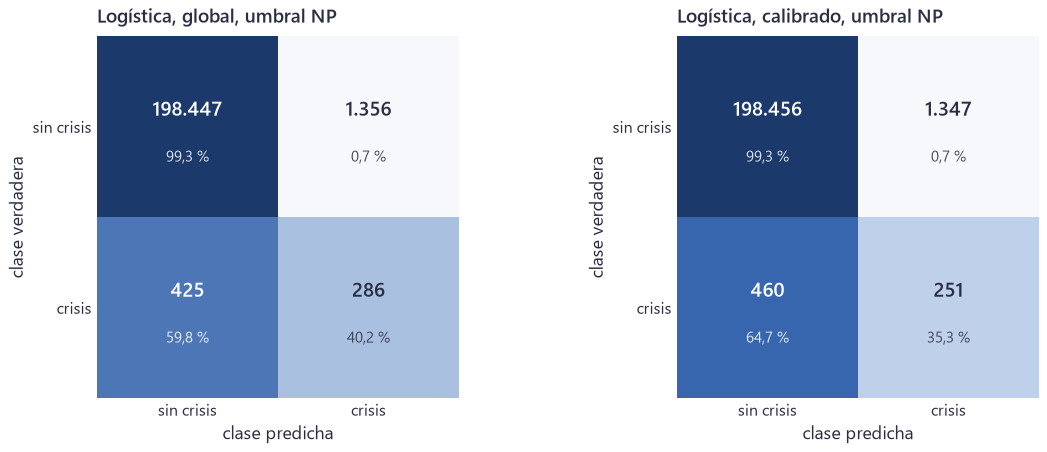

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, var in zip(ejes, VARIANTES):
    cm = np.zeros((2, 2), int)
    for _, r in lopo.query("variante == @var and modelo == 'logistica' and regla == 'neyman_pearson'").iterrows():
        cm += np.array([[r.TN, r.FP], [r.FN, r.TP]])
    EG.matriz_confusion(ax, cm, ["sin crisis", "crisis"], f"Logística, {var}, umbral NP")
fig.tight_layout(); fig.savefig(SALIDA / "chbmit_lopo_confusion.png")

## Parte E — Partición fija (para comparar con la CNN)

Misma partición por paciente que usará la CNN: entrenamiento chb02, chb05, chb08; validación chb01;
prueba chb03, chb10. Acá el umbral de Neyman-Pearson se calcula con las ventanas sin crisis del paciente
de **validación**, igual que se hará con la CNN.

In [18]:
PART = json.loads((RAIZ / "datos" / "chbmit_proc" / "particion.json").read_text(encoding="utf-8"))["fija"]
m_tr = np.isin(pac, PART["entrenamiento"]); m_va = np.isin(pac, PART["validacion"]); m_te = np.isin(pac, PART["prueba"])
filas, guardar = [], {}
for var, F in VARIANTES.items():
    for nombre, modelo in nuevos_modelos().items():
        modelo.fit(F[m_tr & ~borde], ictal[m_tr & ~borde])
        s_va = M.suavizar(modelo.decision_function(F[m_va]), arch[m_va], K_SUAVE)
        s_te = M.suavizar(modelo.decision_function(F[m_te]), arch[m_te], K_SUAVE)
        tau = M.umbral_neyman_pearson(s_va[~ictal[m_va] & ~borde[m_va]], ALFA_NP)
        guardar[f"{var}__{nombre}"] = s_te
        limpio = ~borde[m_te]
        mv, ev, _ = evaluar(s_te, m_te, tau)
        filas.append({"variante": var, "modelo": nombre, "umbral": tau,
                      "AUC_val": roc_auc_score(ictal[m_va][~borde[m_va]], s_va[~borde[m_va]]),
                      "AUC_prueba": roc_auc_score(ictal[m_te][limpio], s_te[limpio]), **mv, **ev})
fija = pd.DataFrame(filas).round(4)
fija.to_csv(SALIDA / "chbmit_particion_fija.csv", index=False)
np.savez_compressed(SALIDA / "chbmit_scores_prueba_fija.npz", indices_prueba=np.where(m_te)[0], **guardar)
fija[["variante", "modelo", "AUC_val", "AUC_prueba", "sensibilidad", "especificidad", "crisis", "detectadas",
      "FA_por_hora", "latencia_mediana_s"]]

,variante,modelo,AUC_val,AUC_prueba,sensibilidad,especificidad,crisis,detectadas,FA_por_hora,latencia_mediana_s
0,global,logistica,0.9689,0.7988,0.3035,0.9849,14,5,3.2583,14.0
1,global,svm_lineal,0.9673,0.7976,0.3035,0.9865,14,7,2.9393,18.0
2,calibrado,logistica,0.9794,0.9342,0.2687,0.9941,14,7,1.2190,26.0
3,calibrado,svm_lineal,0.9769,0.9299,0.2438,0.9946,14,6,1.0026,24.5


**Observaciones:** con solo 3 pacientes de entrenamiento la variante **global** generaliza mal
(AUC de prueba 0,80 contra 0,97 en validación); la variante **calibrada** llega a 0,93. Estas son las
líneas de base contra las que se compara la CNN en la etapa siguiente.

## Guardado

In [19]:
meta = {"bonn": {"atributos": "log10 potencia Welch en 20 bandas de 2 Hz (0,5-40 Hz)", "cv": "10 particiones x 5 repeticiones"},
        "chbmit": {"atributos": "log10 potencia 18 canales x 5 bandas", "alfa_neyman_pearson": ALFA_NP,
                   "suavizado_ventanas": K_SUAVE, "logistica_C": 0.1, "svm_lineal_C": 0.01,
                   "class_weight": "balanced"},
        "optimalidad": {"lambda": LAM, "L": float(L), "iteraciones": ITER, "inicios": 20}}
(SALIDA / "metadatos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(sorted(p.name for p in SALIDA.iterdir()))

['bonn_coeficientes.csv', 'bonn_coeficientes.png', 'bonn_cv_repetida.csv', 'bonn_matrices_confusion.png', 'bonn_metricas_por_clase.csv', 'bonn_roc.png', 'bonn_simplex.png', 'chbmit_lopo_confusion.png', 'chbmit_lopo_detalle.csv', 'chbmit_lopo_eventos.csv', 'chbmit_lopo_resumen.csv', 'chbmit_lopo_roc.png', 'chbmit_particion_fija.csv', 'chbmit_scores_prueba_fija.npz', 'metadatos.json', 'optimalidad_convexo_vs_no_convexo.png', 'svm_kkt.csv', 'svm_kkt.png']
